In [76]:
import sys
sys.path.append('../')

import pandas as pd
import numpy as np
import json
from sqlalchemy import text
from src.db_connect import get_engine
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Create engine
engine = get_engine()


In [73]:
df = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_product_performance;'), con=engine)


In [77]:
df_customer_insights = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_customer_insights;'), con=engine)


In [2]:
# Load all mart tables for comprehensive analysis
df_customer_insights = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_customer_insights;'), con=engine)
df_financial = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_financial_performance;'), con=engine)
df_products = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_product_performance;'), con=engine)
df_business_metrics = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_business_metrics;'), con=engine)
df_geographic = pd.read_sql(text('SELECT * FROM s_hamayunrahimzai.mart_geographic_analysis;'), con=engine)

In [15]:
print(f"✓ Customer Insights: {len(df_customer_insights):,} customers")
print(f"✓ Financial Data: {len(df_financial):,} daily records")
print(f"✓ Product Performance: {len(df_products):,} products")
print(f"✓ Business Metrics: {len(df_business_metrics):,} summary records")
print(f"✓ Geographic Data: {len(df_geographic):,} regions")


✓ Customer Insights: 50,242 customers


NameError: name 'df_financial' is not defined

In [5]:
# Calculate overall business health metrics
total_customers = len(df_customer_insights)
total_revenue = df_customer_insights['monetary'].sum()
avg_order_value = df_customer_insights['monetary'].mean()
active_customers = len(df_customer_insights[df_customer_insights['churn_flag'] == 0])
churn_rate = (df_customer_insights['churn_flag'].sum() / total_customers) * 100

print(f"   • Total Customers: {total_customers:,}")
print(f"   • Active Customers: {active_customers:,} ({(active_customers/total_customers)*100:.1f}%)")
print(f"   • Total Revenue: IDR {total_revenue:,.0f}")
print(f"   • Average Customer Value: IDR {avg_order_value:,.0f}")
print(f"   • Overall Churn Rate: {churn_rate:.1f}%")


   • Total Customers: 50,242
   • Active Customers: 30,533 (60.8%)
   • Total Revenue: IDR 1,421,160,090,713
   • Average Customer Value: IDR 28,286,296
   • Overall Churn Rate: 39.2%


In [7]:
# Segment analysis with business impact
segment_analysis = df_customer_insights.groupby('customer_segment').agg({
    'customer_id': 'count',
    'monetary': ['sum', 'mean'],
    'frequency': 'mean',
    'recency_days': 'mean',
    'churn_flag': 'mean'
}).round(2)

segment_analysis.columns = ['Customer_Count', 'Total_Revenue', 'Avg_Revenue', 'Avg_Frequency', 'Avg_Recency', 'Churn_Rate']
segment_analysis['Revenue_Share'] = (segment_analysis['Total_Revenue'] / segment_analysis['Total_Revenue'].sum() * 100).round(1)
segment_analysis['Customer_Share'] = (segment_analysis['Customer_Count'] / segment_analysis['Customer_Count'].sum() * 100).round(1)
print(segment_analysis)


                  Customer_Count  Total_Revenue  Avg_Revenue  Avg_Frequency  \
customer_segment                                                              
At Risk Customer           17613   1.779068e+10   1010087.99           1.95   
Loyal Customer              8768   1.950577e+11  22246543.91          13.42   
Regular Customer           12025   1.003800e+11   8347611.78           5.46   
VIP Customer               11836   1.107932e+12  93606934.96          50.56   

                  Avg_Recency  Churn_Rate  Revenue_Share  Customer_Share  
customer_segment                                                          
At Risk Customer       671.52        0.88            1.3            35.1  
Loyal Customer          64.12        0.03           13.7            17.5  
Regular Customer       192.69        0.32            7.1            23.9  
VIP Customer            29.22        0.00           78.0            23.6  


# CRITICAL BUSINESS INSIGHTS:

In [8]:
# Insight 1: VIP Customer Dominance
vip_revenue_share = segment_analysis.loc['VIP Customer', 'Revenue_Share']
vip_customer_share = segment_analysis.loc['VIP Customer', 'Customer_Share']

print(f"1. VIP CUSTOMER DOMINANCE:")
print(f"   • {vip_customer_share}% of customers generate {vip_revenue_share}% of revenue")
print(f"   • Revenue per VIP: IDR {segment_analysis.loc['VIP Customer', 'Avg_Revenue']:,.0f}")


1. VIP CUSTOMER DOMINANCE:
   • 23.6% of customers generate 78.0% of revenue
   • Revenue per VIP: IDR 93,606,935


In [9]:
# Insight 2: At-Risk Customer Crisis
at_risk_count = segment_analysis.loc['At Risk Customer', 'Customer_Count']
at_risk_share = segment_analysis.loc['At Risk Customer', 'Customer_Share']
at_risk_churn = segment_analysis.loc['At Risk Customer', 'Churn_Rate']

print(f"\n2. AT-RISK CUSTOMER CRISIS:")
print(f"   • {at_risk_count:,} customers ({at_risk_share}%) are at risk")
print(f"   • {at_risk_churn*100:.0f}% churn rate in this segment")
print(f"   • Immediate intervention required")


2. AT-RISK CUSTOMER CRISIS:
   • 17,613 customers (35.1%) are at risk
   • 88% churn rate in this segment
   • Immediate intervention required


In [10]:
# Insight 3: Regular Customer Opportunity
regular_count = segment_analysis.loc['Regular Customer', 'Customer_Count']
regular_churn = segment_analysis.loc['Regular Customer', 'Churn_Rate']

print(f"\n3. REGULAR CUSTOMER OPPORTUNITY:")
print(f"   • {regular_count:,} regular customers with {regular_churn*100:.1f}% churn")
print(f"   • High potential for upselling to Loyal/VIP status")



3. REGULAR CUSTOMER OPPORTUNITY:
   • 12,025 regular customers with 32.0% churn
   • High potential for upselling to Loyal/VIP status


# COMPREHENSIVE VISUALIZATIONS

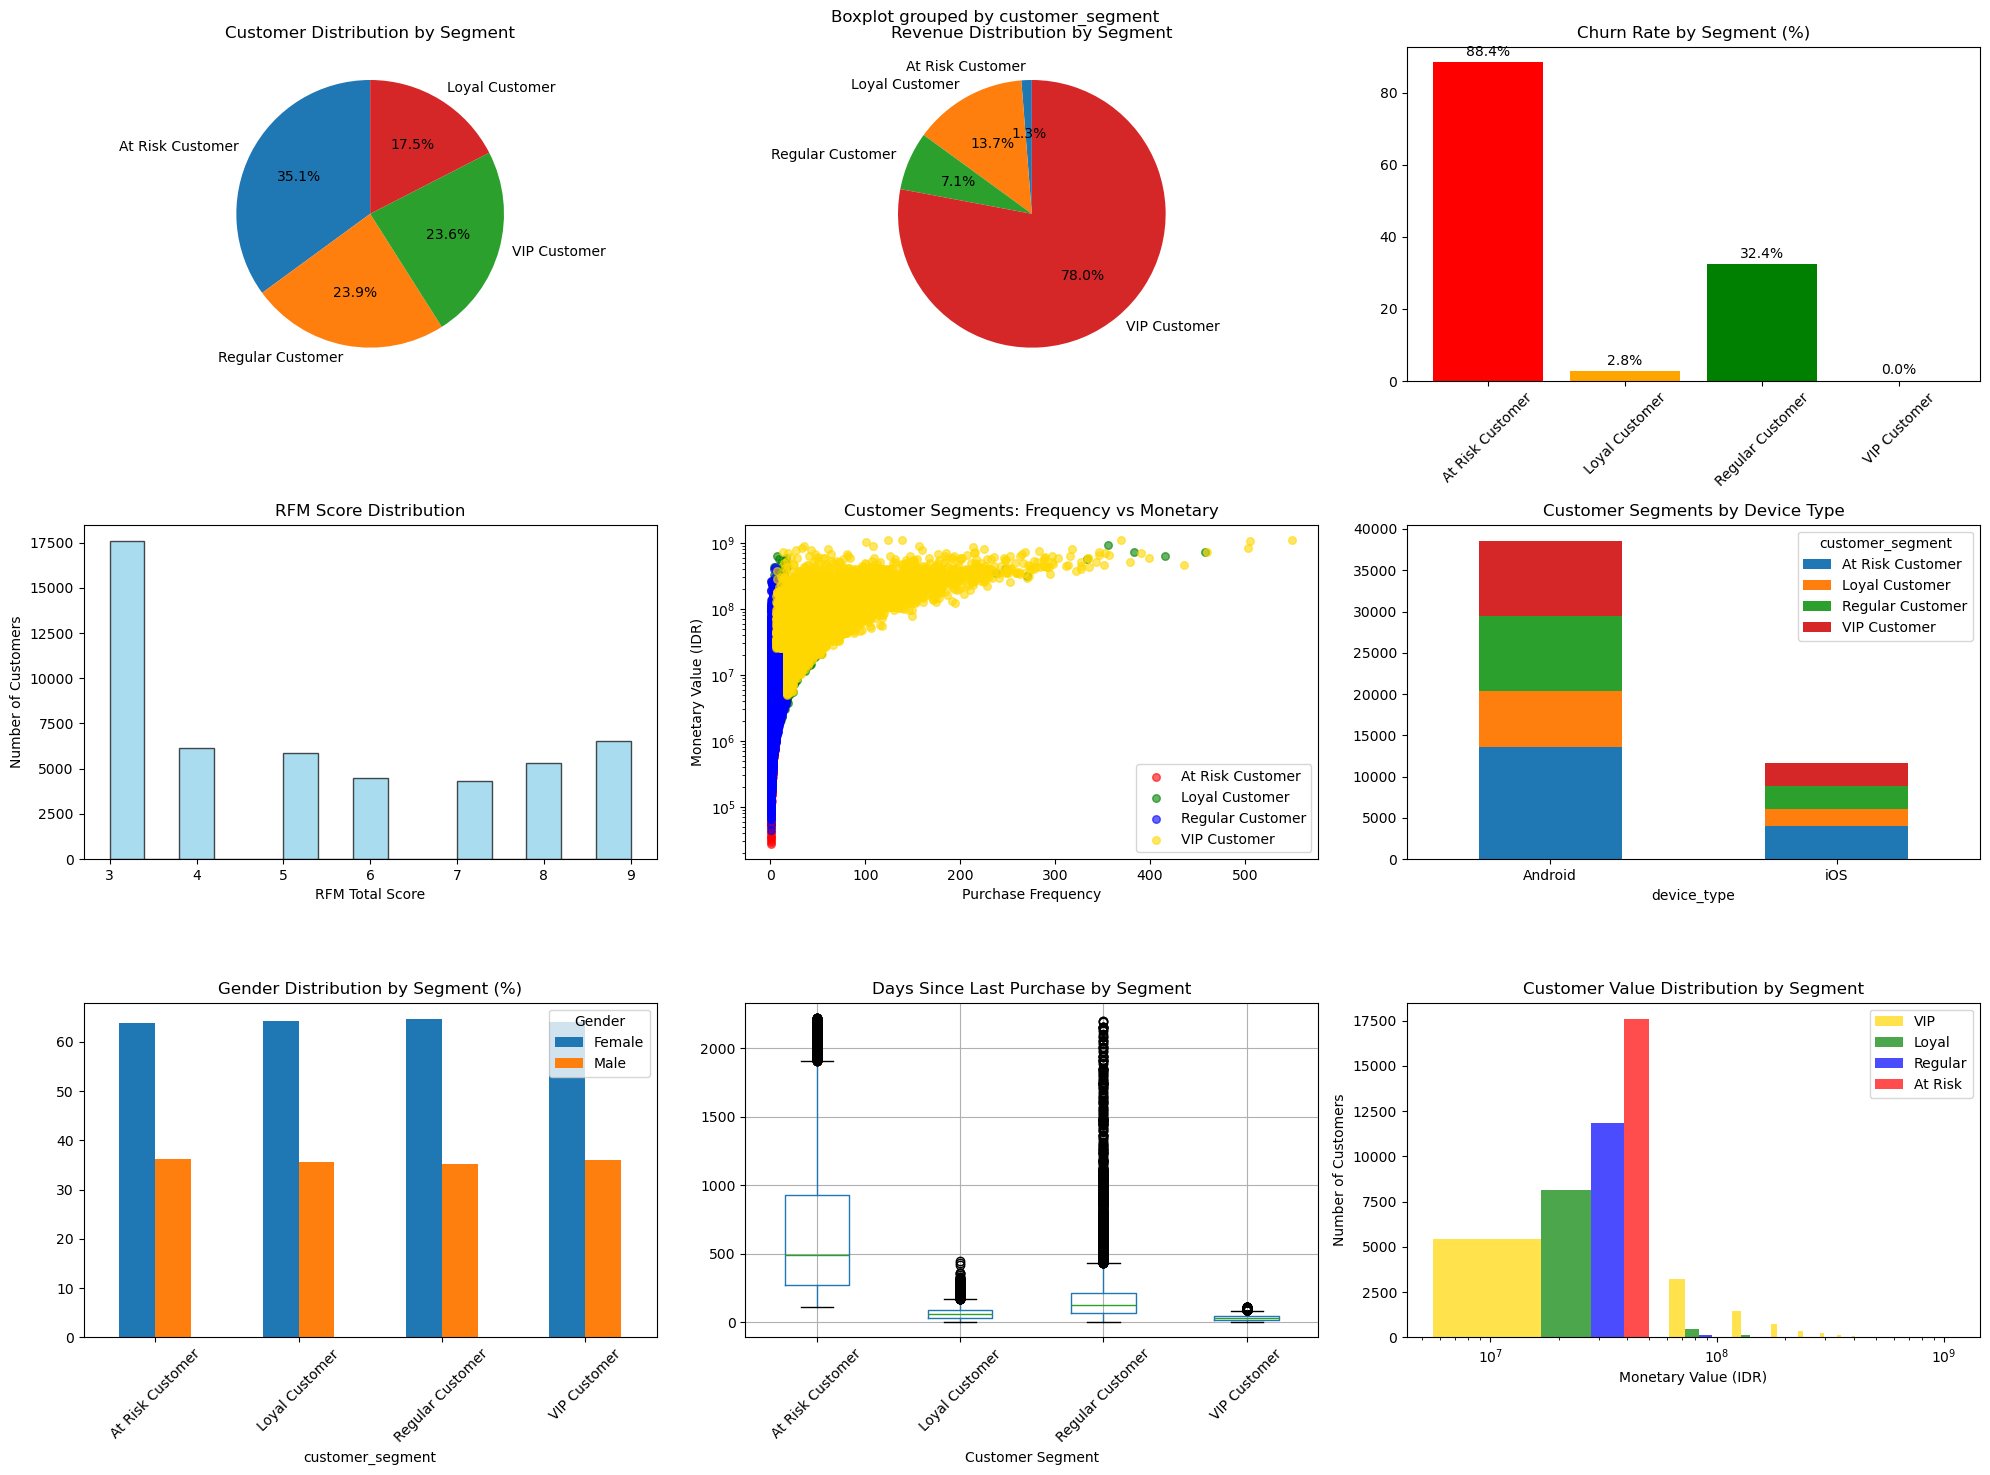

In [12]:
# Create comprehensive business dashboard
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
fig.suptitle('E-COMMERCE CUSTOMER SEGMENTATION - BUSINESS DASHBOARD', fontsize=16, fontweight='bold')

# 1. Segment Distribution (Count)
segment_counts = df_customer_insights['customer_segment'].value_counts()
axes[0,0].pie(segment_counts.values, labels=segment_counts.index, autopct='%1.1f%%', startangle=90)
axes[0,0].set_title('Customer Distribution by Segment')

# 2. Revenue Distribution by Segment
segment_revenue = df_customer_insights.groupby('customer_segment')['monetary'].sum()
axes[0,1].pie(segment_revenue.values, labels=segment_revenue.index, autopct='%1.1f%%', startangle=90)
axes[0,1].set_title('Revenue Distribution by Segment')

# 3. Churn Rate by Segment
churn_by_segment = df_customer_insights.groupby('customer_segment')['churn_flag'].mean() * 100
bars = axes[0,2].bar(churn_by_segment.index, churn_by_segment.values, color=['red', 'orange', 'green', 'gold'])
axes[0,2].set_title('Churn Rate by Segment (%)')
axes[0,2].tick_params(axis='x', rotation=45)
for bar in bars:
    height = bar.get_height()
    axes[0,2].text(bar.get_x() + bar.get_width()/2., height + 1, f'{height:.1f}%', 
                   ha='center', va='bottom')

# 4. RFM Score Distribution
axes[1,0].hist(df_customer_insights['rfm_total'], bins=15, alpha=0.7, color='skyblue', edgecolor='black')
axes[1,0].set_title('RFM Score Distribution')
axes[1,0].set_xlabel('RFM Total Score')
axes[1,0].set_ylabel('Number of Customers')

# 5. Frequency vs Monetary (Scatter)
colors = {'VIP Customer': 'gold', 'Loyal Customer': 'green', 
          'Regular Customer': 'blue', 'At Risk Customer': 'red'}
for segment in df_customer_insights['customer_segment'].unique():
    segment_data = df_customer_insights[df_customer_insights['customer_segment'] == segment]
    axes[1,1].scatter(segment_data['frequency'], segment_data['monetary'], 
                     alpha=0.6, label=segment, c=colors[segment], s=30)
axes[1,1].set_xlabel('Purchase Frequency')
axes[1,1].set_ylabel('Monetary Value (IDR)')
axes[1,1].set_title('Customer Segments: Frequency vs Monetary')
axes[1,1].legend()
axes[1,1].set_yscale('log')

# 6. Device Type Analysis
device_segment = pd.crosstab(df_customer_insights['device_type'], df_customer_insights['customer_segment'])
device_segment.plot(kind='bar', ax=axes[1,2], stacked=True)
axes[1,2].set_title('Customer Segments by Device Type')
axes[1,2].tick_params(axis='x', rotation=0)

# 7. Gender Distribution by Segment
gender_segment = pd.crosstab(df_customer_insights['customer_segment'], df_customer_insights['gender'], normalize='index') * 100
gender_segment.plot(kind='bar', ax=axes[2,0])
axes[2,0].set_title('Gender Distribution by Segment (%)')
axes[2,0].tick_params(axis='x', rotation=45)
axes[2,0].legend(title='Gender')

# 8. Recency Distribution by Segment
df_customer_insights.boxplot(column='recency_days', by='customer_segment', ax=axes[2,1])
axes[2,1].set_title('Days Since Last Purchase by Segment')
axes[2,1].set_xlabel('Customer Segment')
axes[2,1].tick_params(axis='x', rotation=45)

# 9. Customer Lifetime Value Distribution
axes[2,2].hist([
    df_customer_insights[df_customer_insights['customer_segment'] == 'VIP Customer']['monetary'],
    df_customer_insights[df_customer_insights['customer_segment'] == 'Loyal Customer']['monetary'],
    df_customer_insights[df_customer_insights['customer_segment'] == 'Regular Customer']['monetary'],
    df_customer_insights[df_customer_insights['customer_segment'] == 'At Risk Customer']['monetary']
], bins=20, alpha=0.7, label=['VIP', 'Loyal', 'Regular', 'At Risk'], color=['gold', 'green', 'blue', 'red'])
axes[2,2].set_title('Customer Value Distribution by Segment')
axes[2,2].set_xlabel('Monetary Value (IDR)')
axes[2,2].set_ylabel('Number of Customers')
axes[2,2].legend()
axes[2,2].set_xscale('log')

plt.tight_layout()
plt.show()

# FINANCIAL IMPACT ANALYSIS

In [13]:
print("\n💰 FINANCIAL IMPACT ANALYSIS:")
print("-" * 40)

# Calculate revenue impact by segment
segment_financial = df_customer_insights.groupby('customer_segment').agg({
    'monetary': ['sum', 'mean', 'count']
}).round(0)

segment_financial.columns = ['Total_Revenue', 'Avg_Revenue_Per_Customer', 'Customer_Count']
segment_financial['Revenue_Per_Customer_Ratio'] = (segment_financial['Avg_Revenue_Per_Customer'] / 
                                                  segment_financial['Avg_Revenue_Per_Customer'].mean()).round(2)

print("Revenue Impact by Segment:")
print(segment_financial)

# Revenue concentration analysis
print(f"\n📊 REVENUE CONCENTRATION:")
print(f"   • Top 23.6% (VIP) customers contribute {vip_revenue_share:.1f}% of total revenue")
print(f"   • Bottom 35.1% (At Risk) customers contribute only {segment_analysis.loc['At Risk Customer', 'Revenue_Share']:.1f}% of revenue")



💰 FINANCIAL IMPACT ANALYSIS:
----------------------------------------
Revenue Impact by Segment:
                  Total_Revenue  Avg_Revenue_Per_Customer  Customer_Count  \
customer_segment                                                            
At Risk Customer   1.779068e+10                 1010088.0           17613   
Loyal Customer     1.950577e+11                22246544.0            8768   
Regular Customer   1.003800e+11                 8347612.0           12025   
VIP Customer       1.107932e+12                93606935.0           11836   

                  Revenue_Per_Customer_Ratio  
customer_segment                              
At Risk Customer                        0.03  
Loyal Customer                          0.71  
Regular Customer                        0.27  
VIP Customer                            2.99  

📊 REVENUE CONCENTRATION:
   • Top 23.6% (VIP) customers contribute 78.0% of total revenue
   • Bottom 35.1% (At Risk) customers contribute only 1.3% of reve

# ACTIONABLE BUSINESS RECOMMENDATIONS

ACTIONABLE BUSINESS RECOMMENDATIONS

1. IMMEDIATE ACTIONS (Next 30 Days)
   Launch win-back campaign for 17,613 At-Risk customers
   Implement VIP loyalty program for 11,836 high-value customers
   Create mobile-first experience (90% traffic is mobile

2. SHORT-TERM STRATEGIES (Next 90 Days):
   Develop personalized email campaigns by segment
   Implement predictive churn modeling
   Create upselling campaigns for Regular customers

3. LONG-TERM INITIATIVES (Next 6 Months):
   Build comprehensive customer loyalty ecosystem
   Implement dynamic pricing strategies
   Develop cross-selling recommendation engine

In [17]:
#  -- ACTIONABLE BUSINESS RECOMMENDATIONS
'''
1. IMMEDIATE ACTIONS (Next 30 Days)
   Launch win-back campaign for 17,613 At-Risk customers
   Implement VIP loyalty program for 11,836 high-value customers
   Create mobile-first experience (90% traffic is mobile

2. SHORT-TERM STRATEGIES (Next 90 Days):
   Develop personalized email campaigns by segment
   Implement predictive churn modeling
   Create upselling campaigns for Regular customers

3. LONG-TERM INITIATIVES (Next 6 Months):
   Build comprehensive customer loyalty ecosystem
   Implement dynamic pricing strategies
   Develop cross-selling recommendation engine'''

'\n1. IMMEDIATE ACTIONS (Next 30 Days)\n   Launch win-back campaign for 17,613 At-Risk customers\n   Implement VIP loyalty program for 11,836 high-value customers\n   Create mobile-first experience (90% traffic is mobile\n\n2. SHORT-TERM STRATEGIES (Next 90 Days):\n   Develop personalized email campaigns by segment\n   Implement predictive churn modeling\n   Create upselling campaigns for Regular customers\n\n3. LONG-TERM INITIATIVES (Next 6 Months):\n   Build comprehensive customer loyalty ecosystem\n   Implement dynamic pricing strategies\n   Develop cross-selling recommendation engine'

/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/4284159635.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=revenue_data, x='Strategy', y='Avg Revenue per Customer', palette='Blues_d', ax=ax[0])
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/4284159635.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_data, x='Strategy', y='Churn Rate (%)', palette='Reds_r', ax=ax[1])


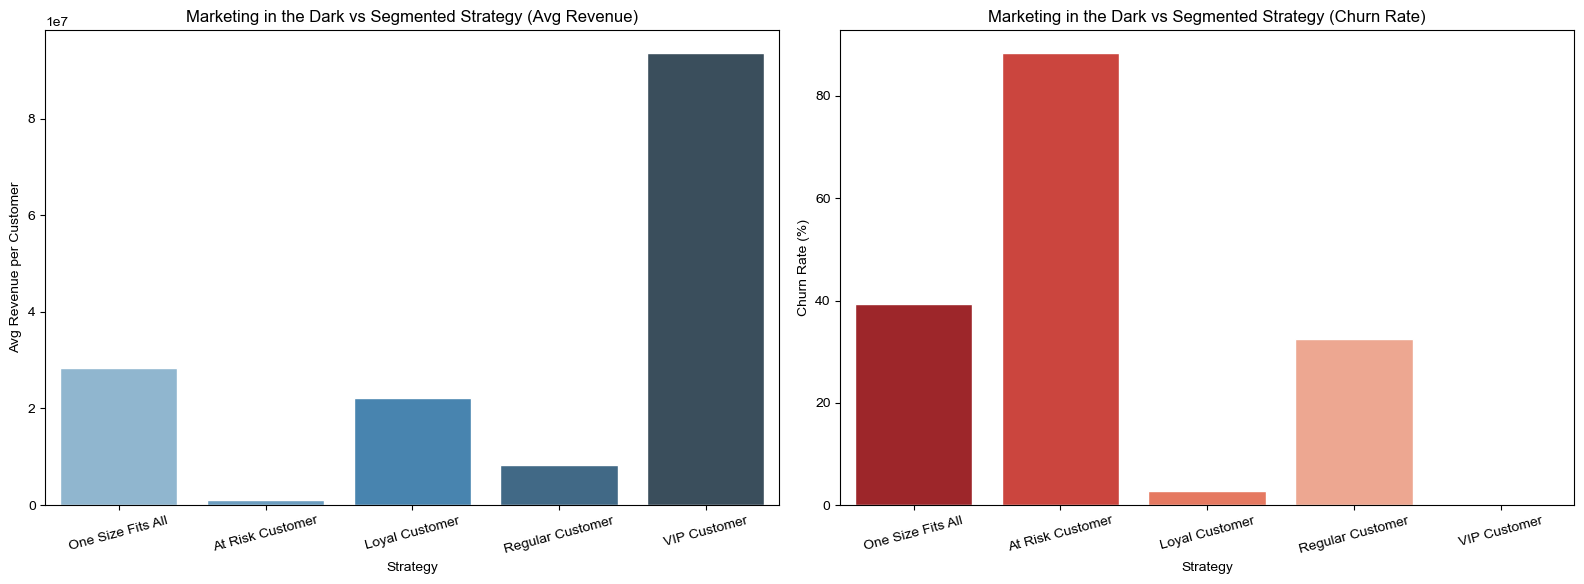

In [3]:
# One Size Fits All - avg revenue and churn
one_size_avg_revenue = df_customer_insights['monetary'].mean()
one_size_churn_rate = df_customer_insights['churn_flag'].mean() * 100  # churn_flag: 1 = churned

# Segmented Strategy
segment_groups = df_customer_insights.groupby('customer_segment')

seg_avg_revenue = segment_groups['monetary'].mean()
seg_churn_rate = segment_groups['churn_flag'].mean() * 100

# --------- Plotting Avg Revenue per Customer ---------
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.set(style="whitegrid")

# Revenue plot
revenue_data = pd.DataFrame({
    'Strategy': ['One Size Fits All'] + seg_avg_revenue.index.tolist(),
    'Avg Revenue per Customer': [one_size_avg_revenue] + seg_avg_revenue.tolist()
})
sns.barplot(data=revenue_data, x='Strategy', y='Avg Revenue per Customer', palette='Blues_d', ax=ax[0])
ax[0].set_title('Marketing in the Dark vs Segmented Strategy (Avg Revenue)')
ax[0].set_ylabel('Avg Revenue per Customer')
ax[0].tick_params(axis='x', rotation=15)

# --------- Plotting Churn Rate ---------
churn_data = pd.DataFrame({
    'Strategy': ['One Size Fits All'] + seg_churn_rate.index.tolist(),
    'Churn Rate (%)': [one_size_churn_rate] + seg_churn_rate.tolist()
})
sns.barplot(data=churn_data, x='Strategy', y='Churn Rate (%)', palette='Reds_r', ax=ax[1])
ax[1].set_title('Marketing in the Dark vs Segmented Strategy (Churn Rate)')
ax[1].set_ylabel('Churn Rate (%)')
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [4]:

# Assuming df is your final customer DataFrame

# Filter customers at 'extreme churn risk'
extreme_risk_customers = df_customer_insights[df_customer_insights['recency_days'] > 180]  # churn_flag == 1

# % of customers at extreme risk
extreme_risk_pct = (len(extreme_risk_customers) / len(df_customer_insights)) * 100

# Churn rate among them
extreme_churn_rate = (extreme_risk_customers['churn_flag'].mean()) * 100

print(f"Extreme Risk Customer Share: {extreme_risk_pct:.2f}%")
print(f"Churn Rate in this Group: {extreme_churn_rate:.2f}%")

Extreme Risk Customer Share: 39.23%
Churn Rate in this Group: 100.00%


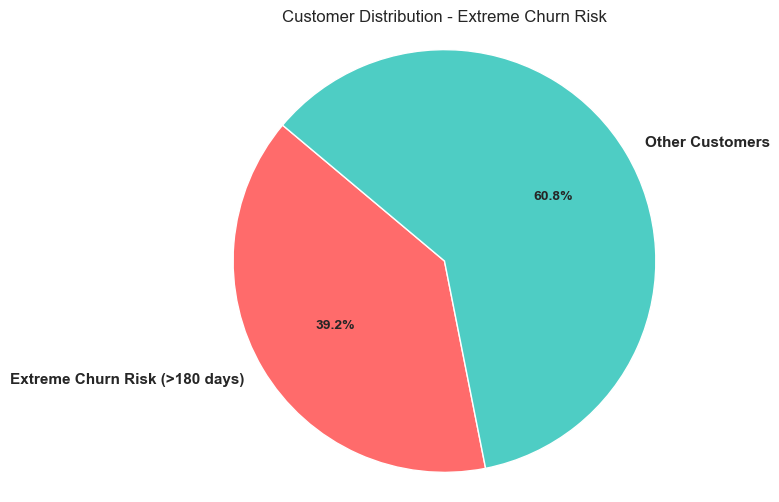

In [112]:
# Pie chart for customer distribution
labels = ['Extreme Churn Risk (>180 days)', 'Other Customers']
sizes = [len(extreme_risk_customers), len(df_customer_insights) - len(extreme_risk_customers)]
colors = ['#FF6B6B', '#4ECDC4']

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)
plt.title('Customer Distribution - Extreme Churn Risk')
plt.axis('equal')
plt.show()

/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/2368167470.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categories, y=values, palette=colors, ax=axs[1])
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/2368167470.py:41: UserWarning: Glyph 128184 (\N{MONEY WITH WINGS}) missing from font(s) Arial.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/2368167470.py:41: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/2368167470.py:41: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Arial.
  plt.tight_layout(rect=[0, 0.05, 1, 0.95])
/opt/anaconda3/lib/python3.12/site-p

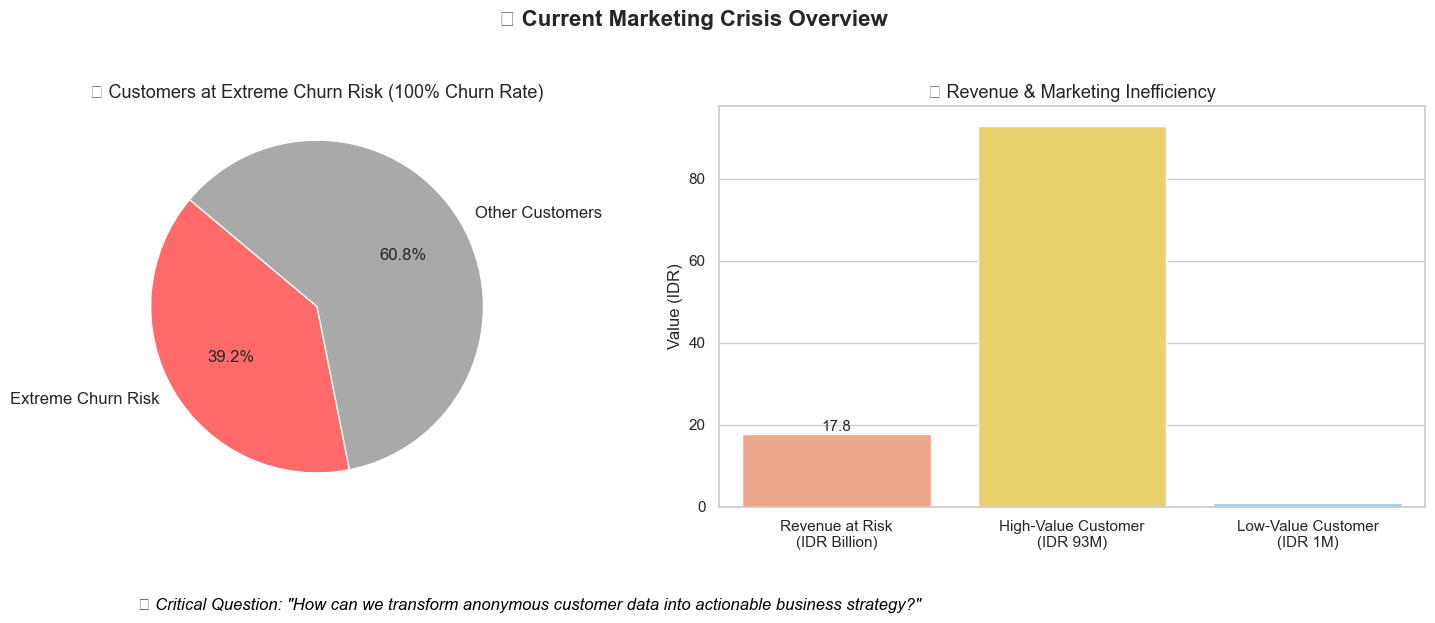

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data
total_customers = 50242
extreme_risk_pct = 39.23
extreme_churn_rate = 100  # stated
revenue_at_risk = 17.8  # in billion IDR
marketing_waste_high = 93  # in million
marketing_waste_low = 1  # in million

# Matplotlib styling
sns.set(style="whitegrid")
fig, axs = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 3]})
fig.suptitle("🚨 Current Marketing Crisis Overview", fontsize=16, weight='bold')

# --- Pie Chart: Extreme Churn Risk ---
labels = ['Extreme Churn Risk', 'Other Customers']
sizes = [extreme_risk_pct, 100 - extreme_risk_pct]
colors = ['#FF6B6B', '#A9A9A9']
axs[0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
           startangle=140, textprops={'fontsize': 12})
axs[0].axis('equal')
axs[0].set_title('💸 Customers at Extreme Churn Risk (100% Churn Rate)', fontsize=13)

# --- Bar Chart: Revenue & Marketing Waste ---
categories = ['Revenue at Risk\n(IDR Billion)', 'High-Value Customer\n(IDR 93M)', 'Low-Value Customer\n(IDR 1M)']
values = [revenue_at_risk, marketing_waste_high, marketing_waste_low]
colors = ['#FFA07A', '#FFDD57', '#87CEFA']

sns.barplot(x=categories, y=values, palette=colors, ax=axs[1])
axs[1].set_ylabel('Value (IDR)', fontsize=12)
axs[1].set_title('📉 Revenue & Marketing Inefficiency', fontsize=13)
axs[1].bar_label(axs[1].containers[0], fmt='%.1f', fontsize=11)

# --- Annotations / Context Box ---
plt.figtext(0.13, -0.02,
            '❓ Critical Question: "How can we transform anonymous customer data into actionable business strategy?"',
            fontsize=12, color='black', style='italic')

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

In [8]:
# Step 1: Basic metrics
avg_revenue_all = df_customer_insights['monetary'].mean()

# Step 2: Revenue per segment
segment_revenue = df_customer_insights.groupby('customer_segment')['monetary'].mean().sort_values(ascending=False)

# Step 3: High vs Low value customer example
# Define "high value" as customers with monetary >= 93M
# Define "low value" as customers with monetary ~ 1M

high_value_customers = df_customer_insights[df_customer_insights['monetary'] >= 93000000]
low_value_customers = df_customer_insights[df_customer_insights['monetary'] <= 1000000]

avg_revenue_high = high_value_customers['monetary'].mean()
avg_revenue_low = low_value_customers['monetary'].mean()

# Step 4: Extreme churn risk customers
extreme_risk_customers = df_customer_insights[df_customer_insights['recency_days'] > 180]
extreme_risk_pct = (len(extreme_risk_customers) / len(df_customer_insights)) * 100
extreme_churn_rate = extreme_risk_customers['churn_flag'].mean() * 100  # Should be 100% as per you

# Step 5: Churn rate per segment
segment_churn_rate = df_customer_insights.groupby('customer_segment')['churn_flag'].mean() * 100


In [20]:
df = df_customer_insights



# One-Size-Fits-All avg revenue
avg_revenue_all = df['monetary'].mean()

# Segment-wise average revenue
segment_revenue = df.groupby('customer_segment')['monetary'].mean()

# Define high-value and low-value customers
high_value_customers = df[df['monetary'] >= 93000000]
low_value_customers = df[df['monetary'] <= 1000000]

avg_revenue_high = high_value_customers['monetary'].mean()
avg_revenue_low = low_value_customers['monetary'].mean()

# Churn info
extreme_churn_customers = df[df['recency_days'] > 90]
extreme_churn_pct = round(len(extreme_churn_customers) / len(df) * 100, 2)
extreme_churn_rate = round(extreme_churn_customers['churn_flag'].mean() * 100, 2)

# Segment-wise churn rate
segment_churn_rate = df.groupby('customer_segment')['churn_flag'].mean() * 100

# Revenue Comparison Table
revenue_comparison = pd.DataFrame({
    'Strategy': ['One-Size-Fits-All', 'Segmented (VIP)', 'Segmented (Loyal)', 'Segmented (Regular)', 'Segmented (At Risk)'],
    'Avg Revenue per Customer (IDR)': [
        round(avg_revenue_all, 0),
        round(segment_revenue.get('VIP Customer', 0), 0),
        round(segment_revenue.get('Loyal Customer', 0), 0),
        round(segment_revenue.get('Regular Customer', 0), 0),
        round(segment_revenue.get('At Risk Customer', 0), 0),
    ]
})

# Churn Comparison Table
churn_comparison = pd.DataFrame({
    'Segment': ['All Customers (OSFA)', 'VIP Customer', 'Loyal Customer', 'Regular Customer', 'At Risk Customer'],
    'Churn Rate (%)': [
        f"{extreme_churn_rate}%" if 'All' in 'All Customers (OSFA)' else '',
        f"{round(segment_churn_rate.get('VIP Customer', 0), 2)}%",
        f"{round(segment_churn_rate.get('Loyal Customer', 0), 2)}%",
        f"{round(segment_churn_rate.get('Regular Customer', 0), 2)}%",
        f"{round(segment_churn_rate.get('At Risk Customer', 0), 2)}%",
    ]
})

# High vs Low Value Table
value_comparison = pd.DataFrame({
    'Customer Type': ['High Value (≥ IDR 93M)', 'Low Value (≤ IDR 1M)'],
    'Avg Revenue (IDR)': [round(avg_revenue_high, 0), round(avg_revenue_low, 0)]
})

# Display all tables
print("📊 Revenue Comparison Table:")
display(revenue_comparison)

print("\n📉 Churn Rate Comparison Table:")
display(churn_comparison)

print("\n💰 High vs Low Value Customers:")
display(value_comparison)


📊 Revenue Comparison Table:


,Strategy,Avg Revenue per Customer (IDR)
0,One-Size-Fits-All,28286296.0
1,Segmented (VIP),93606935.0
2,Segmented (Loyal),22246544.0
3,Segmented (Regular),8347612.0
4,Segmented (At Risk),1010088.0



📉 Churn Rate Comparison Table:


,Segment,Churn Rate (%)
0,All Customers (OSFA),100.0%
1,VIP Customer,1.57%
2,Loyal Customer,22.24%
3,Regular Customer,65.17%
4,At Risk Customer,100.0%



💰 High vs Low Value Customers:


,Customer Type,Avg Revenue (IDR)
0,High Value (≥ IDR 93M),189511452.0
1,Low Value (≤ IDR 1M),432171.0


In [29]:
summary_table = pd.DataFrame({
    'Metric': [
        'Report Name',
        'Total Customers',
        'Total Orders',
        'Total Revenue (IDR)',
        'Avg Order Value (IDR)',
        'Revenue per Customer (IDR)',
        'First Transaction Date',
        'Last Transaction Date',
        'Business Days Active'
    ],
    'Value': [
        df_mart_executive_summary.loc[0, 'report_name'],
        f"{df_mart_executive_summary.loc[0, 'total_customers']:,}",
        f"{df_mart_executive_summary.loc[0, 'total_orders']:,}",
        f"IDR {df_mart_executive_summary.loc[0, 'total_revenue']:,}",
        f"IDR {df_mart_executive_summary.loc[0, 'avg_order_value']:,}",
        f"IDR {df_mart_executive_summary.loc[0, 'revenue_per_customer']:,}",
        df_mart_executive_summary.loc[0, 'first_transaction_date'],
        df_mart_executive_summary.loc[0, 'last_transaction_date'],
        f"{df_mart_executive_summary.loc[0, 'business_days_active']} days"
    ]
})

print(summary_table)

                       Metric                      Value
0                 Report Name  Business Health Dashboard
1             Total Customers                     50,242
2                Total Orders                    815,964
3         Total Revenue (IDR)    IDR 1,421,160,090,713.0
4       Avg Order Value (IDR)            IDR 1,183,279.5
5  Revenue per Customer (IDR)          IDR 28,286,296.14
6      First Transaction Date                 2016-06-30
7       Last Transaction Date                 2022-07-31
8        Business Days Active                  2222 days


/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/492660885.py:69: UserWarning: Glyph 128101 (\N{BUSTS IN SILHOUETTE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/492660885.py:69: UserWarning: Glyph 128179 (\N{CREDIT CARD}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/492660885.py:69: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/492660885.py:69: UserWarning: Glyph 128197 (\N{CALENDAR}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/492660885.py:69: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()


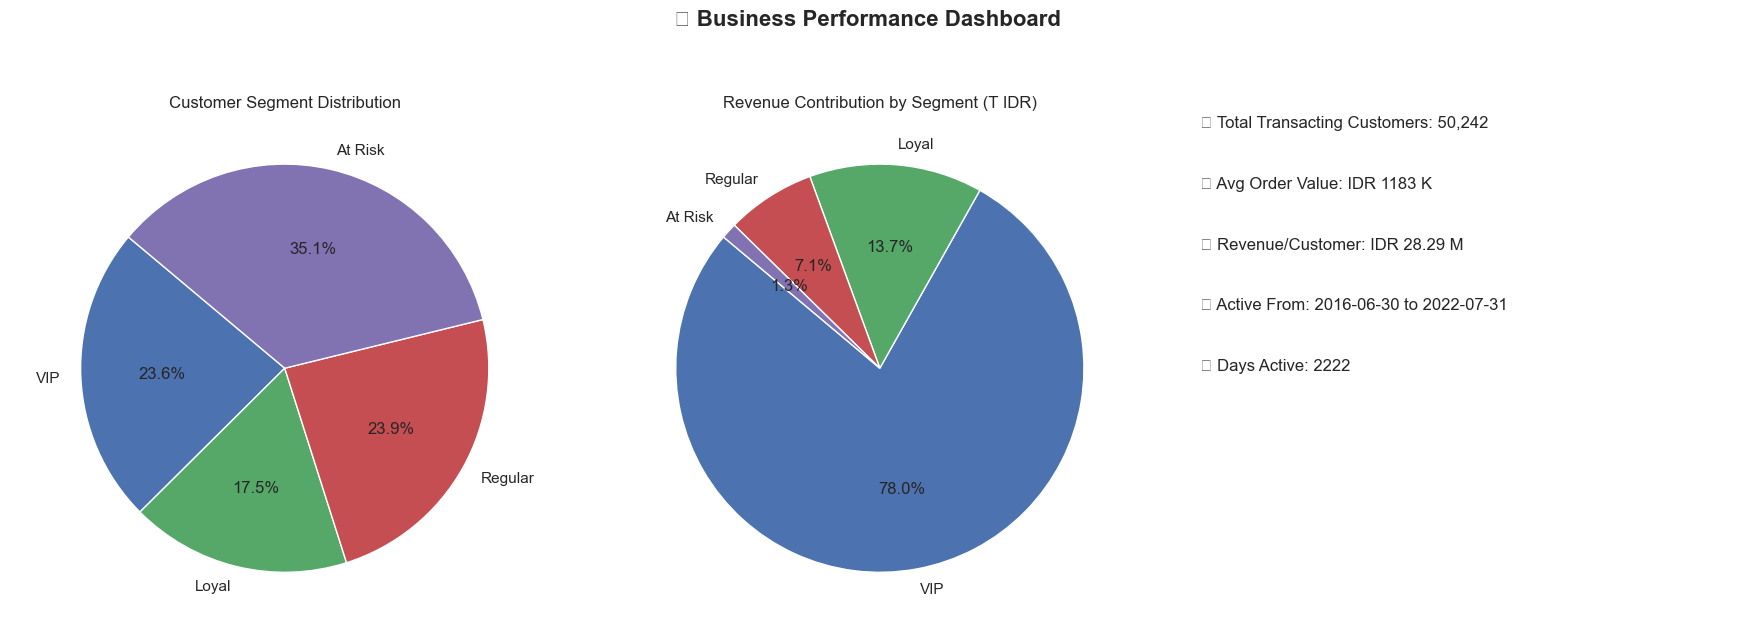

In [32]:

# Executive Summary Data
executive_metrics = {
    'Total Customers': 50242,
    'Total Orders': 815964,
    'Total Revenue (IDR)': 1_421_160_090_713,
    'Avg Order Value (IDR)': 1_183_279.5,
    'Revenue per Customer (IDR)': 28286296.14,
    'First Transaction Date': '2016-06-30',
    'Last Transaction Date': '2022-07-31',
    'Business Days Active': 2222
}

# Customer Segments and Revenue
segment_counts = {
    'VIP': 11836,
    'Loyal': 8768,
    'Regular': 12025,
    'At Risk': 17613
}

segment_revenue = {
    'VIP': 1107931682241.0,
    'Loyal': 195057696962.0,
    'Regular': 100380031658.0,
    'At Risk': 17790679852.0
}

# -------------------------------
# 2. Plotting Dashboard
# -------------------------------
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
plt.suptitle("📊 Business Performance Dashboard", fontsize=16, fontweight='bold', y=1.05)

# ---- Pie Chart 1: Customer Segments ----
axs[0].pie(segment_counts.values(), 
           labels=segment_counts.keys(), 
           autopct='%1.1f%%', 
           startangle=140, 
           colors=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
axs[0].axis('equal')
axs[0].set_title('Customer Segment Distribution')

# ---- Pie Chart 2: Revenue by Segment ----
rev_trillion = {k: v / 1e12 for k, v in segment_revenue.items()}
axs[1].pie(rev_trillion.values(), 
           labels=rev_trillion.keys(), 
           autopct='%1.1f%%', 
           startangle=140,
           colors=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
axs[1].axis('equal')
axs[1].set_title('Revenue Contribution by Segment (T IDR)')

# ---- KPI Panel ----
axs[2].axis('off')
kpis = [
    f"👥 Total Transacting Customers: {executive_metrics['Total Customers']:,}",
    f"💳 Avg Order Value: IDR {executive_metrics['Avg Order Value (IDR)'] / 1e3:.0f} K",
    f"📊 Revenue/Customer: IDR {executive_metrics['Revenue per Customer (IDR)'] / 1e6:.2f} M",
    f"📅 Active From: {executive_metrics['First Transaction Date']} to {executive_metrics['Last Transaction Date']}",
    f"📈 Days Active: {executive_metrics['Business Days Active']}"
]

# Add text to KPI panel
y = 1.0
for kpi in kpis:
    axs[2].text(0, y, kpi, fontsize=12, va='top')
    y -= 0.12

plt.tight_layout()
plt.show()

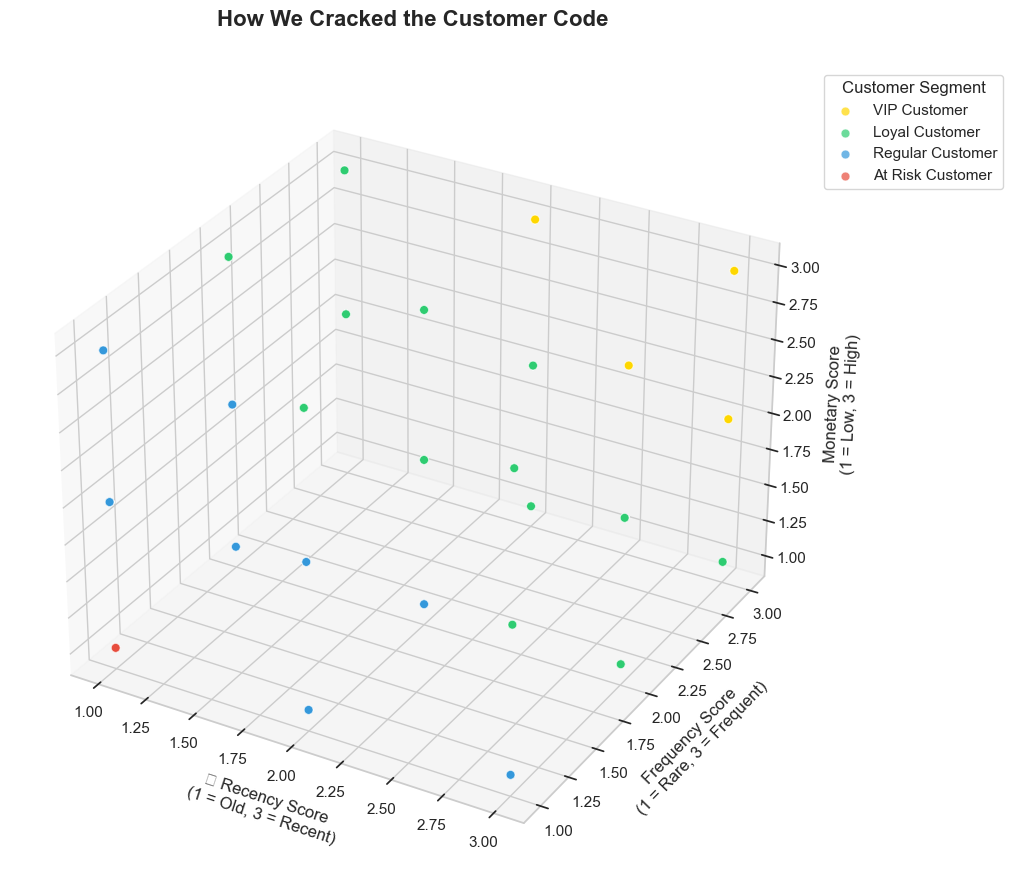

In [ ]:
df = df_customer_insights

segment_colors = {
    'VIP Customer': '#FFD700',     
    'Loyal Customer': '#2ecc71',   
    'Regular Customer': '#3498db', 
    'At Risk Customer': '#e74c3c'  
}

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for segment, color in segment_colors.items():
    seg_data = df[df['customer_segment'] == segment]
    ax.scatter(
        seg_data['recency_score'],
        seg_data['frequency_score'],
        seg_data['monetary_score'],
        label=segment,
        color=color,
        s=40,
        alpha=0.7,
        edgecolors='w',
        linewidths=0.5
    )

ax.set_xlabel('📅 Recency Score\n(1 = Old, 3 = Recent)', labelpad=10)
ax.set_ylabel('Frequency Score\n(1 = Rare, 3 = Frequent)', labelpad=10)
ax.set_zlabel('Monetary Score\n(1 = Low, 3 = High)', labelpad=10)
ax.set_title('How We Cracked the Customer Code', fontsize=16, fontweight='bold', pad=30)

ax.legend(title='Customer Segment', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [43]:
df[['avg_days_to_deliver', 'total_revenue']].corr()

,avg_days_to_deliver,total_revenue
avg_days_to_deliver,1.000000,-0.000468
total_revenue,-0.000468,1.000000


/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


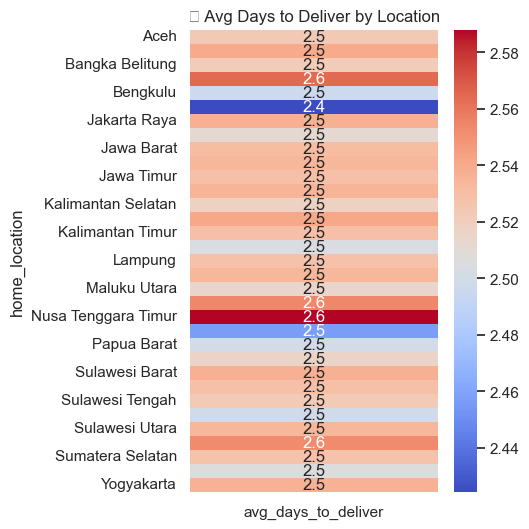

In [46]:
heatmap_data = df.pivot_table(values='avg_days_to_deliver', index='home_location', aggfunc='mean')
plt.figure(figsize=(4, 6))
sns.heatmap(heatmap_data, annot=True, cmap='coolwarm', fmt=".1f")
plt.title("📍 Avg Days to Deliver by Location")
plt.show()

In [58]:
df = df_customer_insights

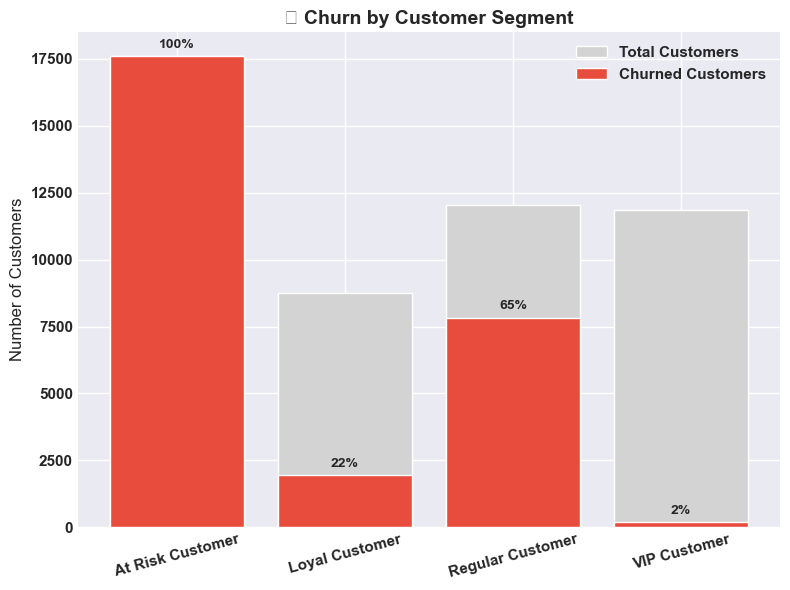

In [113]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Base bar: total customers
plt.bar(segment_stats['customer_segment'], segment_stats['total_customers'], color='#d3d3d3', label='Total Customers')

# Overlay bar: churned customers
plt.bar(segment_stats['customer_segment'], segment_stats['churned'], color='#e74c3c', label='Churned Customers')

# Add % labels
for idx, row in segment_stats.iterrows():
    plt.text(idx, row['churned'] + 300, f"{row['churn_rate']:.0%}", ha='center', fontsize=10, fontweight='bold')

# Chart styling
plt.title('📉 Churn by Customer Segment', fontsize=14, fontweight='bold')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()




/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/3200065266.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  delivery_grouped = df.groupby('delivery_speed')['total_revenue'].sum().reset_index()
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/3200065266.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=delivery_grouped, x='delivery_speed', y='total_revenue', palette='Blues_d')
/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/3200065266.py:16: UserWarning: Glyph 128230 (\N{PACKAGE}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylab

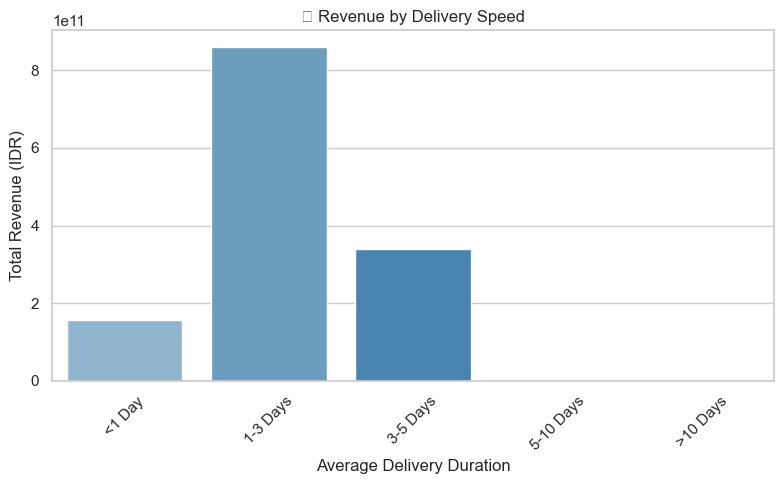

In [67]:
# Bin avg_days_to_deliver into delivery speed categories
df['delivery_speed'] = pd.cut(df['avg_days_to_deliver'], 
                              bins=[0, 1, 3, 5, 10, float('inf')],
                              labels=['<1 Day', '1-3 Days', '3-5 Days', '5-10 Days', '>10 Days'])

# Group and aggregate
delivery_grouped = df.groupby('delivery_speed')['total_revenue'].sum().reset_index()

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(data=delivery_grouped, x='delivery_speed', y='total_revenue', palette='Blues_d')
plt.title('📦 Revenue by Delivery Speed')
plt.ylabel('Total Revenue (IDR)')
plt.xlabel('Average Delivery Duration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [83]:
df = df_customer_insights

# Filter only 'At Risk Customer' segment
at_risk_df = df[df['customer_segment'] == 'At Risk Customer']

# 🚨 Total customers at immediate risk
at_risk_count = at_risk_df['customer_id'].nunique()

# ⏰ Average days since last purchase
avg_recency = at_risk_df['recency_days'].mean()

# 💸 Total revenue at stake
revenue_at_risk = at_risk_df['monetary'].sum()

# 📉 Churn rate in this segment
churned_count = at_risk_df[at_risk_df['churn_flag'] == 1]['customer_id'].nunique()
churn_rate = churned_count / at_risk_count * 100

# 🖨️ Display the facts
print("🔍 Churn Crisis Fact Check")
print(f"🚨 Customers at risk           : {at_risk_count:,}")
print(f"⏰ Avg days since last purchase: {avg_recency:.0f} days")
print(f"💸 Revenue at stake            : IDR {revenue_at_risk:,.0f}")
print(f"📉 Churn rate in segment       : {churn_rate:.2f}%")


🔍 Churn Crisis Fact Check
🚨 Customers at risk           : 17,613
⏰ Avg days since last purchase: 672 days
💸 Revenue at stake            : IDR 17,790,679,852
📉 Churn rate in segment       : 100.00%


/var/folders/2d/6kky53r90h312l6jvp5rdjh80000gn/T/ipykernel_57978/421470391.py:29: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


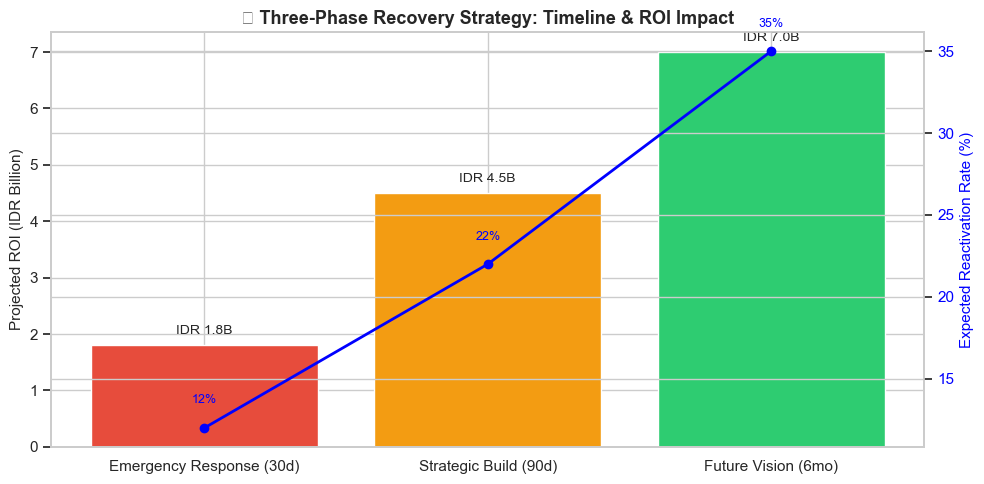

In [85]:
# Step 1: Create a DataFrame with the data
data = {
    'Phase': ['Emergency Response (30d)', 'Strategic Build (90d)', 'Future Vision (6mo)'],
    'ROI_Billion_IDR': [1.8, 4.5, 7.0],
    'Reactivation_Rate': [0.12, 0.22, 0.35]
}
df = pd.DataFrame(data)

# Step 2: Setup figure and axes
fig, ax1 = plt.subplots(figsize=(10, 5))

# Step 3: Bar chart for ROI
bars = ax1.bar(df['Phase'], df['ROI_Billion_IDR'], color=['#e74c3c', '#f39c12', '#2ecc71'])
ax1.set_ylabel('Projected ROI (IDR Billion)', fontsize=11)
ax1.set_title('📈 Three-Phase Recovery Strategy: Timeline & ROI Impact', fontsize=13, fontweight='bold')

# Step 4: Line chart for Reactivation Rate (%)
ax2 = ax1.twinx()
ax2.plot(df['Phase'], df['Reactivation_Rate'] * 100, color='blue', marker='o', linewidth=2, label='Reactivation Rate')
ax2.set_ylabel('Expected Reactivation Rate (%)', fontsize=11, color='blue')
ax2.tick_params(axis='y', labelcolor='blue')

# Step 5: Add labels above bars and points
for i in range(len(df)):
    ax1.text(i, df['ROI_Billion_IDR'][i] + 0.2, f"IDR {df['ROI_Billion_IDR'][i]:.1f}B", ha='center', fontsize=10)
    ax2.text(i, df['Reactivation_Rate'][i]*100 + 1.5, f"{df['Reactivation_Rate'][i]*100:.0f}%", ha='center', color='blue', fontsize=9)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()